# 03 · Cell-type dynamics and neural loss at the wound

Neoblasts accumulate at the wound from 12 hpa to 3 dpa (`02_wound_region_neoblasts.ipynb`). To rebuild the lost tissue, they must then differentiate into specific cell types. This notebook first asks which differentiated cell types change the most over the time course, and then follows the most dynamic one, neurons, to see whether their loss and recovery happen at the wound or across the whole body.

**Steps**

1. Cell-type proportions per spot
2. Changes in cell-type composition over time
3. Neurons near and away from the wound

**Input:** `data/Scanpy_Visium/Visium_*.h5ad` and `data/processed/02_wound_regions.csv`.

## Setup

Load the same section per timepoint as in `02_wound_region_neoblasts.ipynb`, together with the wound labels saved there. Shared loading code is in `notebooks/common.py`.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import stats

from common import (CELL_TYPES, HOURS, TICK_LBL, TP_ORDER, cell_props,
                    load_blast, load_sections)

sc.settings.verbosity = 0
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

sections = load_sections()
for tp, sec in sections.items():
    print(f"{tp}: {sec.n_obs} spots, {sec.obs['wound_proximal'].sum()} wound-proximal")

0hpa: 977 spots, 265 wound-proximal
6hpa: 870 spots, 108 wound-proximal
12hpa: 1115 spots, 313 wound-proximal
1dpa: 901 spots, 128 wound-proximal
3dpa: 1231 spots, 367 wound-proximal
7dpa: 1176 spots, 337 wound-proximal


## 1. Cell-type proportions per spot

**What.** Each spot comes with cell2location estimates for seven major planarian cell types (epidermal, gut, muscle, neoblast, neuronal, parenchymal, secretory). Dividing each estimate by the spot's total gives the proportion of each cell type in that spot.

**Why proportions.** Spots hold different numbers of cells. Proportions remove that difference, so spots and timepoints can be compared directly.

In [2]:
props = {tp: cell_props(sec) for tp, sec in sections.items()}

mean_df = pd.DataFrame({tp: p.mean() for tp, p in props.items()}).T
mean_df.index.name = 'timepoint'
print('Mean proportion per spot:')
print(mean_df.round(3).to_string())

Mean proportion per spot:
           Epidermal    Gut  Muscle  Neoblast  Neuronal  Parenchymal  Secretory
timepoint                                                                      
0hpa           0.034  0.173   0.066     0.160     0.204        0.115      0.248
6hpa           0.044  0.156   0.065     0.195     0.133        0.112      0.295
12hpa          0.069  0.062   0.077     0.174     0.303        0.128      0.188
1dpa           0.052  0.071   0.061     0.288     0.202        0.122      0.204
3dpa           0.031  0.097   0.076     0.262     0.155        0.129      0.249
7dpa           0.033  0.050   0.054     0.271     0.259        0.114      0.219


## 2. Changes in cell-type composition over time

**What.** For each cell type, test whether its per-spot proportion differs across the six timepoints, and plot the mean proportions as a heatmap and as trajectories.

**Test.** Kruskal–Wallis, one test per cell type. It is the rank-based version of one-way ANOVA. Proportions are bounded between 0 and 1, skewed, and contain many near-zero values, so the normality assumption of ANOVA does not hold.

**Plots.** The heatmap shows which cell types dominate at which timepoints. The line plot shows the shape of each trajectory (steady, peaked, or V-shaped), which the heatmap hides.

Kruskal-Wallis test (H0: same distribution at all timepoints):
             KW_statistic        p_value  range_of_means
cell_type                                               
Epidermal           357.8   3.601233e-75           0.038
Gut                1224.5  1.420341e-262           0.123
Muscle              273.6   4.692260e-57           0.023
Neoblast            480.1  1.568500e-101           0.128
Neuronal            367.0   3.848448e-77           0.171
Parenchymal          94.6   7.309937e-19           0.018
Secretory            98.8   9.257564e-20           0.108


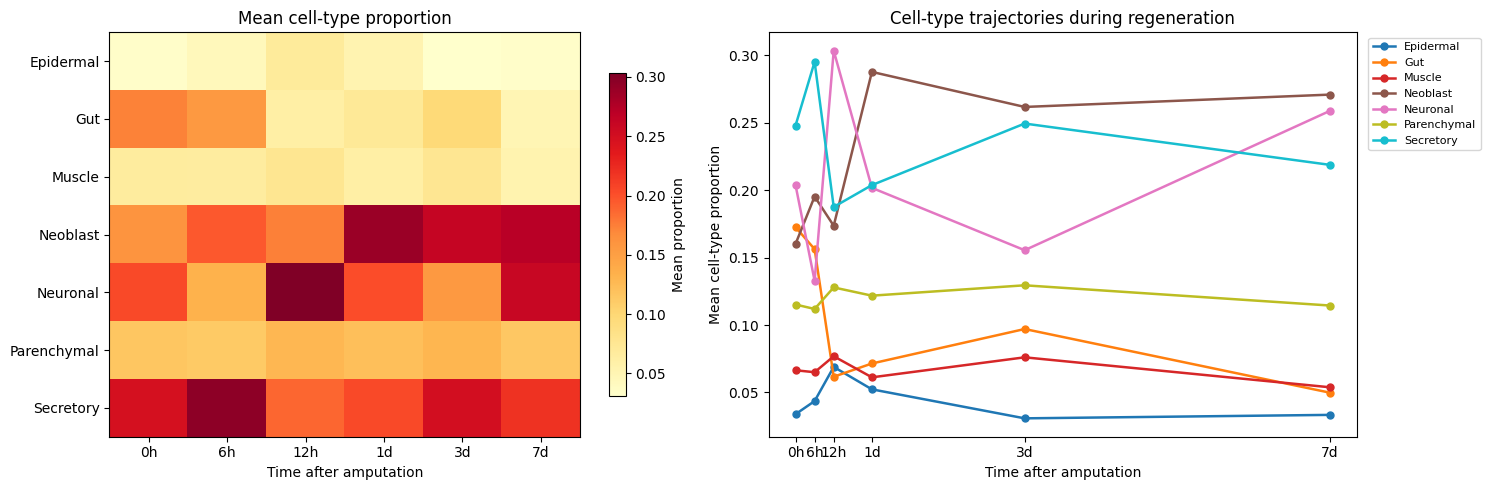

In [3]:
kw_rows = []
for ct in CELL_TYPES:
    stat, pval = stats.kruskal(*[props[tp][ct].values for tp in TP_ORDER])
    kw_rows.append({'cell_type': ct, 'KW_statistic': round(stat, 1), 'p_value': pval,
                    'range_of_means': round(mean_df[ct].max() - mean_df[ct].min(), 3)})
kw_df = pd.DataFrame(kw_rows).set_index('cell_type')
print('Kruskal-Wallis test (H0: same distribution at all timepoints):')
print(kw_df.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

im = axes[0].imshow(mean_df[CELL_TYPES].values.T, aspect='auto', cmap='YlOrRd')
axes[0].set_xticks(range(len(TP_ORDER)))
axes[0].set_xticklabels(TICK_LBL)
axes[0].set_yticks(range(len(CELL_TYPES)))
axes[0].set_yticklabels(CELL_TYPES)
axes[0].set_xlabel('Time after amputation')
axes[0].set_title('Mean cell-type proportion')
plt.colorbar(im, ax=axes[0], shrink=0.8, label='Mean proportion')

colors = plt.cm.tab10(np.linspace(0, 1, len(CELL_TYPES)))
for ct, color in zip(CELL_TYPES, colors):
    axes[1].plot(HOURS, mean_df[ct].values, 'o-', label=ct, color=color,
                 linewidth=1.8, markersize=5)
axes[1].set_xticks(HOURS)
axes[1].set_xticklabels(TICK_LBL)
axes[1].set_xlabel('Time after amputation')
axes[1].set_ylabel('Mean cell-type proportion')
axes[1].set_title('Cell-type trajectories during regeneration')
axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/03_celltype_kinetics.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** - All seven cell types change significantly over time (Kruskal–Wallis p < 10⁻¹⁸ for each), so amputation remodels the whole fragment, not only the stem-cell compartment.
- Neurons change the most (range of means 0.17). They peak at 12 hpa (0.30), fall to a low point at 3 dpa (0.16), and recover by 7 dpa (0.26).
- Neoblasts rise from 0.16 at 0 hpa to 0.29 at 1 dpa and stay high (0.26–0.27) through 7 dpa.
- Gut drops from 0.17 to 0.06 by 12 hpa and stays low, reflecting the loss of intestine at the cut surfaces.
- Secretory cells vary moderately (range 0.11). Epidermal, muscle, and parenchymal cells change little (range below 0.04).

Neurons are the most dynamic differentiated cell type, so the rest of the analysis follows them.

## 3. Neurons near and away from the wound

**What.** In each section, compare the neuronal proportion of wound-proximal and wound-distal spots.

**Why.** The drop and recovery of neurons in Section 2 can be explained in two ways:
- **Local loss and replacement.** Cutting removes neurons at the cut surfaces, and new neurons are later produced there. Neurons should then be depleted at the wound early on and restored, or even enriched, there later.
- **Dilution.** Expanding neoblasts make up a larger share of every spot, so the neuronal proportion drops everywhere without any change in where neurons are. Wound and distal spots should then look the same at every timepoint.

Comparing wound and distal spots at each timepoint separates the two.

**Test.** Two-sided Mann–Whitney U (Wilcoxon rank-sum). Unlike the neoblast test in notebook 02, both directions are plausible here (depletion from tissue loss, enrichment from new neurons), so the test should not assume one. The direction is read from the two means.

Neuronal proportion: wound-proximal vs wound-distal (two-sided Mann-Whitney U)
timepoint  mean_wound  mean_distal direction      p_value
     0hpa       0.318        0.161  enriched 2.809676e-04
     6hpa       0.113        0.136  depleted 3.233949e-01
    12hpa       0.237        0.329  depleted 6.909938e-13
     1dpa       0.164        0.208  depleted 1.163598e-04
     3dpa       0.153        0.157  depleted 8.641087e-01
     7dpa       0.342        0.226  enriched 9.178640e-04


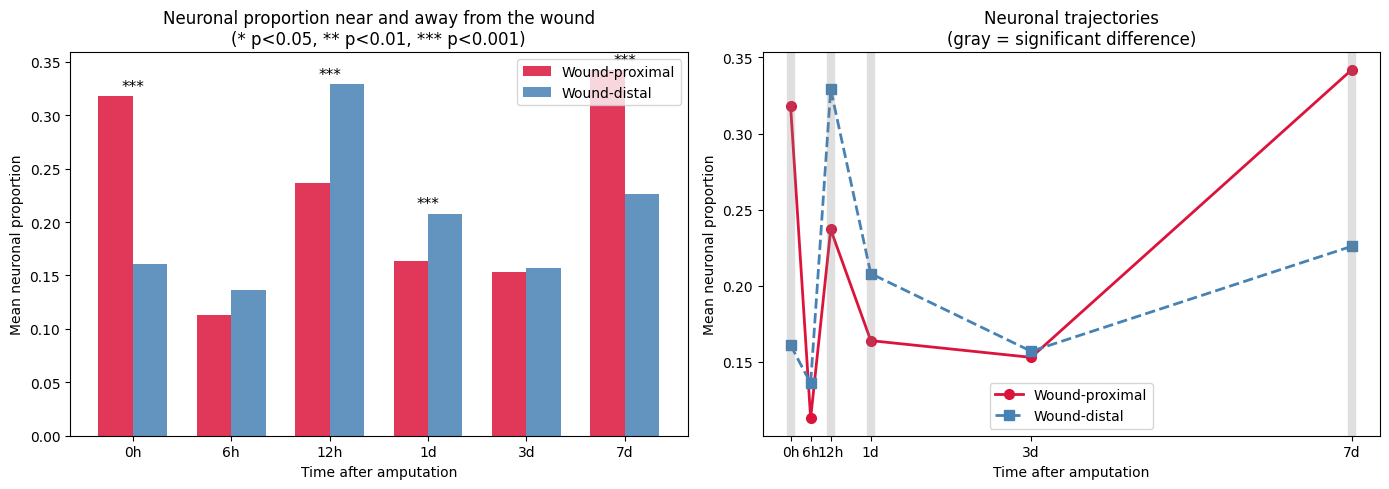

In [4]:
neuro_records = []
for tp, sec in sections.items():
    neuro = props[tp]['Neuronal'].values
    mask = sec.obs['wound_proximal'].values
    wound_v, distal_v = neuro[mask], neuro[~mask]
    _, pval = stats.mannwhitneyu(wound_v, distal_v, alternative='two-sided')
    neuro_records.append({
        'timepoint': tp,
        'mean_wound': round(wound_v.mean(), 3),
        'mean_distal': round(distal_v.mean(), 3),
        'direction': 'enriched' if wound_v.mean() > distal_v.mean() else 'depleted',
        'p_value': pval,
    })
neuro_df = pd.DataFrame(neuro_records)
print('Neuronal proportion: wound-proximal vs wound-distal (two-sided Mann-Whitney U)')
print(neuro_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(TP_ORDER))
w = 0.35
axes[0].bar(x - w / 2, neuro_df['mean_wound'], w, label='Wound-proximal',
            color='crimson', alpha=0.85)
axes[0].bar(x + w / 2, neuro_df['mean_distal'], w, label='Wound-distal',
            color='steelblue', alpha=0.85)
for i, row in neuro_df.iterrows():
    if row['p_value'] < 0.05:
        stars = '***' if row['p_value'] < 0.001 else ('**' if row['p_value'] < 0.01 else '*')
        axes[0].text(i, max(row['mean_wound'], row['mean_distal']) + 0.005, stars,
                     ha='center', fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(TICK_LBL)
axes[0].set_xlabel('Time after amputation')
axes[0].set_ylabel('Mean neuronal proportion')
axes[0].set_title('Neuronal proportion near and away from the wound\n'
                  '(* p<0.05, ** p<0.01, *** p<0.001)')
axes[0].legend()

axes[1].plot(HOURS, neuro_df['mean_wound'], 'o-', color='crimson', linewidth=2,
             markersize=7, label='Wound-proximal')
axes[1].plot(HOURS, neuro_df['mean_distal'], 's--', color='steelblue', linewidth=2,
             markersize=7, label='Wound-distal')
for h, p in zip(HOURS, neuro_df['p_value']):
    if p < 0.05:
        axes[1].axvline(h, color='gray', alpha=0.25, linewidth=6)
axes[1].set_xticks(HOURS)
axes[1].set_xticklabels(TICK_LBL)
axes[1].set_xlabel('Time after amputation')
axes[1].set_ylabel('Mean neuronal proportion')
axes[1].set_title('Neuronal trajectories\n(gray = significant difference)')
axes[1].legend()
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/03_neurons_wound_vs_distal.png', dpi=150, bbox_inches='tight')
plt.show()

**Result.** The direction of the difference changes over the time course:

| Timepoint | Wound | Distal | Direction | p-value |
|-----------|-------|--------|-----------|---------|
| 0 hpa | 0.318 | 0.161 | enriched | 2.8 × 10⁻⁴ |
| 6 hpa | 0.113 | 0.136 | depleted | 0.32 |
| 12 hpa | 0.237 | 0.329 | depleted | 6.9 × 10⁻¹³ |
| 1 dpa | 0.164 | 0.208 | depleted | 1.2 × 10⁻⁴ |
| 3 dpa | 0.153 | 0.157 | – | 0.86 |
| 7 dpa | 0.342 | 0.226 | enriched | 9.2 × 10⁻⁴ |

- **0 hpa, baseline.** Before any wound response, the wound regions sit at the head and tail ends, which are naturally rich in neurons (brain at the front, nerve plexus at both ends). This is the reference level.
- **6 hpa to 1 dpa, loss at the wound.** Neurons are depleted at the wound, significantly at 12 hpa and 1 dpa, while the distal tissue is not.
- **3 dpa, low everywhere.** Both regions are at the same low level. The low point in Section 2 is therefore partly body-wide, likely because neoblasts take up a larger share of every spot at this stage.
- **7 dpa, recovery at the wound.** The wound reaches 0.34, slightly above its 0 hpa level, while the distal tissue reaches only 0.23.

Neurons are lost at the wound and then rebuilt there. A pure dilution effect would not produce opposite differences at different timepoints, so it can be ruled out as the main explanation.

## Summary

- Amputation changes the proportions of all seven cell types. Neurons change the most among differentiated cells, with a peak at 12 hpa, a low point at 3 dpa, and recovery by 7 dpa.
- Neuronal loss and recovery happen at the wound: neurons are depleted there at 12 hpa and 1 dpa and are enriched there again by 7 dpa (0.34 vs 0.23 distal).

**Next:** `04_neural_spatial_organization.ipynb` asks how the wound is refilled with neurons.